# 01 · Análise Exploratória — Indicador Criança Alfabetizada

**Tech Challenge Fase 3 · POSTECH FIAP (1IAST)** · fonte: pipeline da Fase 2 —
[TECH_CHALLENGE_FASE2_PIPELINE](https://github.com/postechfiap018-ctrl/TECH_CHALLENGE_FASE2_PIPELINE)

Objetivo deste notebook: entender a camada **Gold** gerada na Fase 2, identificar padrões, distribuições e correlações,
formular **hipóteses analíticas** e — principalmente — tomar as **decisões de modelagem** (alvo, features, tratamento de
*data leakage* e estratégia de validação) que serão usadas no notebook 02.

As tabelas abaixo são a **camada analítica** da Fase 3. Quando o data lake é o da pipeline oficial (AWS), elas são derivadas
de `silver/resultado_municipio`, `silver/metas_*`, `silver/alunos` e validadas contra `gold/comparacao_metas_resultados`
por `src/preprocessing/fase2_adapter.py`; na execução local da Fase 2 já vêm prontas na Gold.

| Tabela analítica | Granularidade | Uso neste projeto |
|---|---|---|
| `indicador_municipio` | município × ano × rede | histórico municipal, metas, gaps |
| `perfil_alunos_municipio` | município × ano × rede | participação, proficiência média |
| `metas_vs_resultados_uf` | UF × ano | contexto estadual |
| `evolucao_temporal` | Brasil/UF × ano | tendência |
| `silver/alunos` | aluno (≈ 2 mi/ano) | **alvo** `alfabetizado` e contexto da escola |
| Fontes externas (IBGE) | município | população, PIB per capita, geografia |

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.preprocessing.load import load_gold, load_alunos
from src.preprocessing.external import build_external_features
from src.preprocessing.features import build_municipal_profile
from src.visualization import plots as vp

vp.set_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("Data lake da Fase 2:", config.DATALAKE, "| layout:", config.FASE2_LAYOUT)
print("Repositório da Fase 2:", config.FASE2_REPO_URL)

Data lake da Fase 2: /home/claude/tech-challenge-fase3/data | layout: local
Repositório da Fase 2: https://github.com/postechfiap018-ctrl/TECH_CHALLENGE_FASE2_PIPELINE


## 1. Visão geral das tabelas Gold

In [2]:
gold = {n: load_gold(n) for n in ["indicador_municipio", "perfil_alunos_municipio", "metas_vs_resultados_uf", "evolucao_temporal"]}
pd.DataFrame({n: {"linhas": len(d), "colunas": d.shape[1], "anos": sorted(d["ano"].unique().tolist())} for n, d in gold.items()}).T

,linhas,colunas,anos
indicador_municipio,24203,19,"[2023, 2024, 2025]"
perfil_alunos_municipio,12417,11,"[2023, 2024]"
metas_vs_resultados_uf,49,14,"[2023, 2024]"
evolucao_temporal,74,5,"[2023, 2024, 2025]"


In [3]:
ind = gold["indicador_municipio"]
display(ind.head())
pd.crosstab(ind["ano"], [ind["origem"], ind["rede"]])

,ano,id_municipio,sigla_uf,rede,origem,taxa_alfabetizacao,media_portugues,meta_ano,meta_2030,gap_meta_ano,gap_meta_2030,atingiu_meta_ano,meta_alfabetizacao_2024,meta_alfabetizacao_2025,meta_alfabetizacao_2026,meta_alfabetizacao_2027,meta_alfabetizacao_2028,meta_alfabetizacao_2029,meta_alfabetizacao_2030
0,2023,1100031,RO,Municipal,batch,69.10,767.88,NaN,80.00,NaN,-10.90,None,70.85,72.53,74.15,75.71,77.21,78.64,80.00
1,2023,1100072,RO,Municipal,batch,58.20,747.89,NaN,80.00,NaN,-21.80,None,61.82,65.31,68.64,71.79,74.74,77.48,80.00
2,2023,1100189,RO,Pública,batch,69.73,762.41,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2023,1101609,RO,Municipal,batch,50.70,745.68,NaN,80.00,NaN,-29.30,None,55.53,60.25,64.80,69.09,73.07,76.71,80.00
4,2023,1101807,RO,Municipal,batch,55.69,752.37,NaN,80.00,NaN,-24.31,None,59.72,63.63,67.37,70.89,74.18,77.22,80.00


origem    batch                         streaming
rede   Estadual Municipal Pública Total Municipal
ano                                              
2023       1149      5448    4950     0         0
2024       1086      5448    5516   398         0
2025          0         0       0     0       208

> **Leitura:** 2023 e 2024 são resultados oficiais (batch). Os 208 registros de 2025 vêm do **streaming simulado** da Fase 2 —
> por serem sintéticos, **não** são usados como alvo de treino nem de avaliação; servem apenas de ilustração.

## 2. Qualidade dos dados e valores ausentes

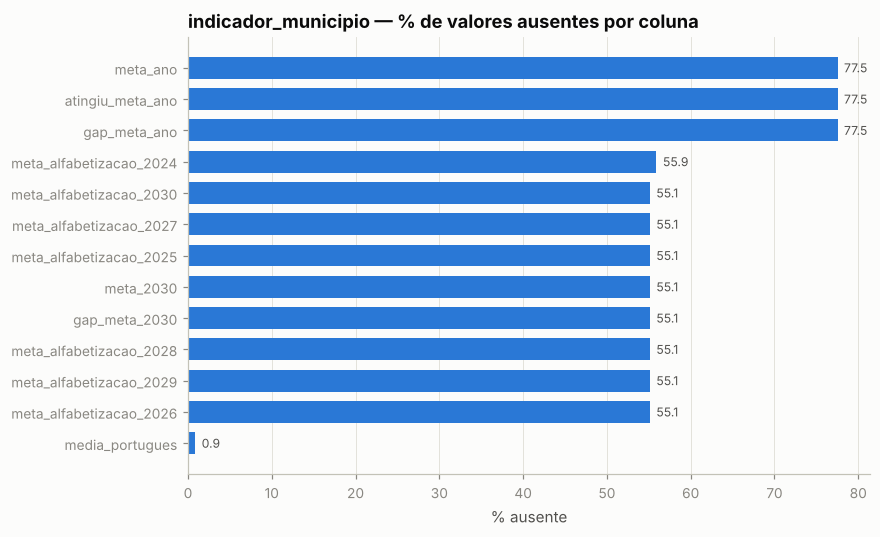

In [4]:
nulos = (ind.isna().mean() * 100).sort_values(ascending=False)
ax = vp.barh(nulos[nulos > 0], "indicador_municipio — % de valores ausentes por coluna", "% ausente")
vp.save(ax.figure, "eda_nulos_indicador")
plt.show()

In [5]:
alunos24 = load_alunos(2024)
print(f"Alunos 2024: {len(alunos24):,}".replace(",", "."))
print("Presentes:", f"{alunos24['presenca'].mean():.1%}")
print(pd.crosstab(alunos24["presenca"], alunos24["alfabetizado"], margins=True))
print("Proficiência ausente entre presentes:", f"{alunos24.loc[alunos24.presenca==1, 'proficiencia'].isna().mean():.2%}")

Alunos 2024: 2.120.560
Presentes: 87.4%


alfabetizado        0        1      All
presenca                               
0              267772        0   267772
1              745669  1107119  1852788
All           1013441  1107119  2120560
Proficiência ausente entre presentes: 0.05%


**Achado crítico de qualidade:** todo aluno **ausente** tem `alfabetizado = 0` — não porque não saiba ler, mas porque não fez
a prova. Usar esses registros criaria um **alvo falso**. Decisão: **modelar apenas alunos presentes** (alvo observado).

## 3. Variável-alvo e tendência nacional

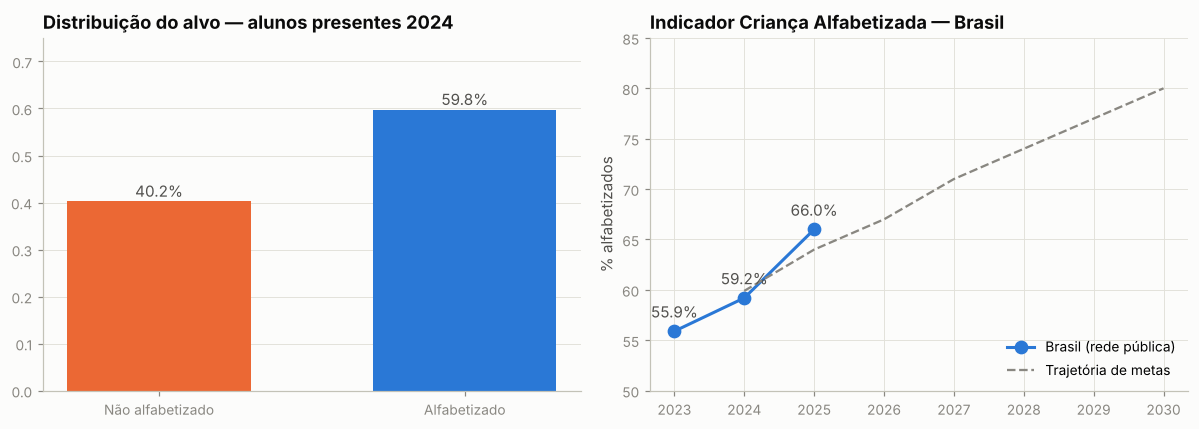

In [6]:
presentes = alunos24[alunos24.presenca == 1]
evo = gold["evolucao_temporal"]
br = evo[evo.nivel == "Brasil"].sort_values("ano")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
taxa = presentes["alfabetizado"].mean()
axes[0].bar(["Não alfabetizado", "Alfabetizado"], [1 - taxa, taxa], color=[vp.CAT[1], vp.CAT[0]], width=0.6)
for i, v in enumerate([1 - taxa, taxa]):
    axes[0].text(i, v + 0.01, f"{v:.1%}", ha="center", color=vp.INK2)
axes[0].set(title="Distribuição do alvo — alunos presentes 2024", ylim=(0, 0.75))
axes[0].grid(axis="x", visible=False)

axes[1].plot(br["ano"], br["taxa_alfabetizacao"], marker="o", ms=8, color=vp.CAT[0], label="Brasil (rede pública)")
metas_br = {2024: 59.9, 2025: 64, 2026: 67, 2027: 71, 2028: 74, 2029: 77, 2030: 80}
axes[1].plot(list(metas_br), list(metas_br.values()), ls="--", color=vp.MUTED, lw=1.5, label="Trajetória de metas")
for x, y in zip(br["ano"], br["taxa_alfabetizacao"]):
    axes[1].annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", color=vp.INK2)
axes[1].set(title="Indicador Criança Alfabetizada — Brasil", ylabel="% alfabetizados", ylim=(50, 85))
axes[1].set_xticks(range(2023, 2031))
axes[1].legend(loc="lower right")
fig.tight_layout(); vp.save(fig, "eda_alvo_tendencia"); plt.show()

O alvo é **moderadamente desbalanceado** (~60/40) — não exige *resampling*, mas pede métricas além da acurácia
(ROC-AUC, acurácia balanceada, recall da classe "não alfabetizado") e escolha cuidadosa do limiar.

## 4. Desigualdade territorial — UFs e regiões

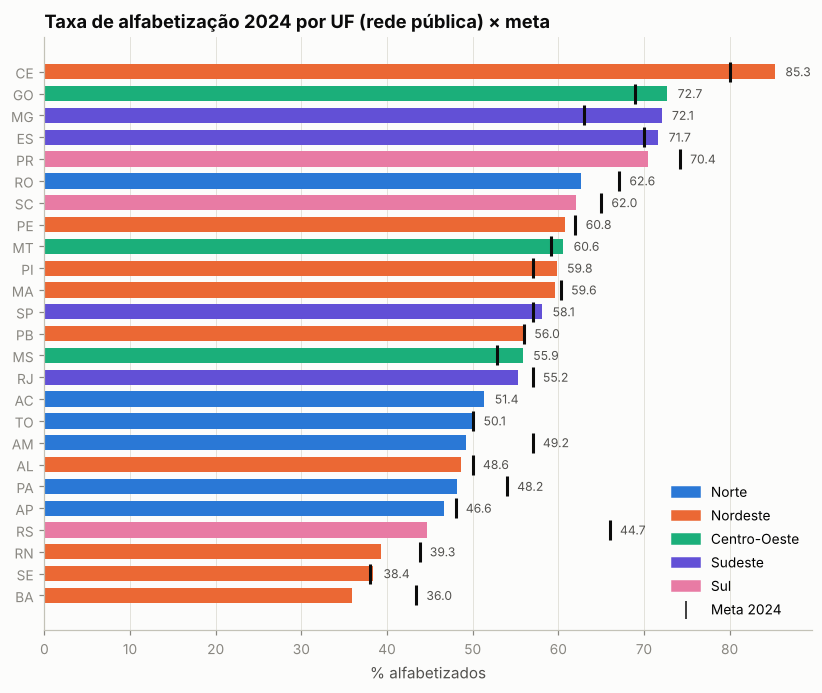

UFs que atingiram a meta 2024: 10 de 24


In [7]:
uf = gold["metas_vs_resultados_uf"]
uf24 = uf[uf.ano == 2024].set_index("sigla_uf").sort_values("taxa_alfabetizacao")
fig, ax = plt.subplots(figsize=(9, 7))
cores = [vp.REGIAO_COR[config.UF_REGIAO[u]] for u in uf24.index]
ax.barh(uf24.index, uf24["taxa_alfabetizacao"], color=cores, height=0.7)
ax.scatter(uf24["meta_alfabetizacao_2024"], uf24.index, marker="|", s=180, color=vp.INK, label="Meta 2024", zorder=3)
for i, (v, m) in enumerate(zip(uf24["taxa_alfabetizacao"], uf24["meta_alfabetizacao_2024"].fillna(0))):
    ax.text(max(v, m) + 1.2, i, f"{v:.1f}", va="center", fontsize=8, color=vp.INK2)
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
handles = [Patch(color=c, label=r) for r, c in vp.REGIAO_COR.items()] + [plt.Line2D([], [], marker="|", ls="", color=vp.INK, ms=12, label="Meta 2024")]
ax.legend(handles=handles, loc="lower right")
ax.set(title="Taxa de alfabetização 2024 por UF (rede pública) × meta", xlabel="% alfabetizados")
vp.save(fig, "eda_uf_2024"); plt.show()
print("UFs que atingiram a meta 2024:", int((uf24.taxa_alfabetizacao >= uf24.meta_alfabetizacao_2024).sum()), "de", uf24.meta_alfabetizacao_2024.notna().sum())

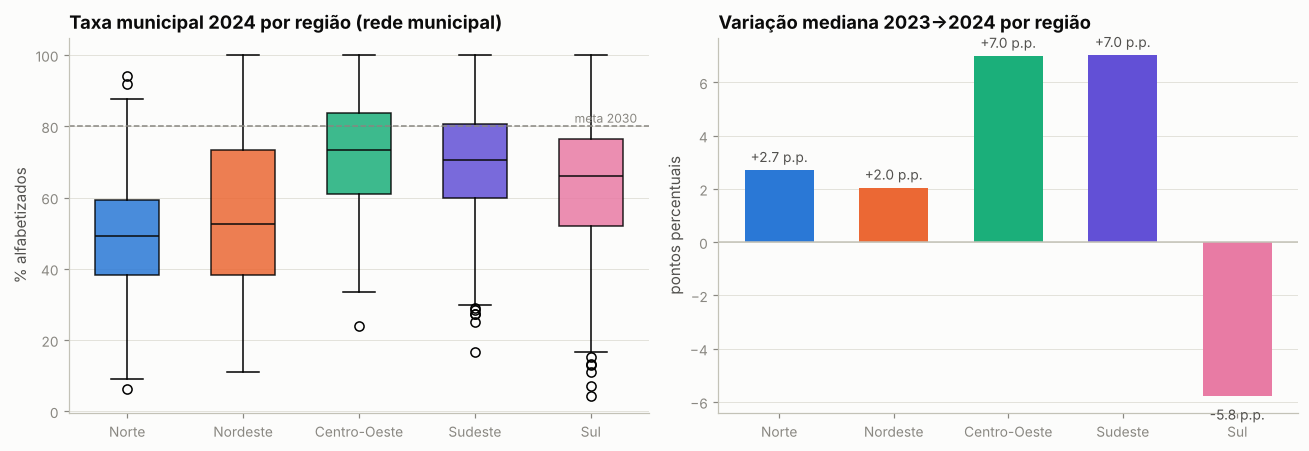

,taxa_2023,taxa_2024,evolucao_23_24,participacao_2024
regiao,,,,
Norte,46.05,49.19,2.71,86.92
Nordeste,48.89,52.63,2.05,94.78
Centro-Oeste,65.51,73.34,7.00,93.33
Sudeste,61.44,70.65,7.03,91.55
Sul,73.34,66.10,-5.76,88.40


In [8]:
prof = build_municipal_profile()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ordem = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
data = [prof.loc[prof.regiao == r, "taxa_2024"].dropna() for r in ordem]
bp = axes[0].boxplot(data, tick_labels=ordem, patch_artist=True, widths=0.55, medianprops=dict(color=vp.INK))
for patch, r in zip(bp["boxes"], ordem):
    patch.set_facecolor(vp.REGIAO_COR[r]); patch.set_alpha(0.85)
axes[0].axhline(80, ls="--", color=vp.MUTED, lw=1); axes[0].text(5.4, 81, "meta 2030", color=vp.MUTED, fontsize=8, ha="right")
axes[0].set(title="Taxa municipal 2024 por região (rede municipal)", ylabel="% alfabetizados")
axes[0].grid(axis="x", visible=False)

med = prof.groupby("regiao")["evolucao_23_24"].median().reindex(ordem)
axes[1].bar(ordem, med, color=[vp.REGIAO_COR[r] for r in ordem], width=0.6)
for i, v in enumerate(med):
    axes[1].text(i, v + (0.3 if v >= 0 else -0.9), f"{v:+.1f} p.p.", ha="center", color=vp.INK2, fontsize=9)
axes[1].axhline(0, color=vp.AXIS, lw=1)
axes[1].set(title="Variação mediana 2023→2024 por região", ylabel="pontos percentuais")
axes[1].grid(axis="x", visible=False)
fig.tight_layout(); vp.save(fig, "eda_regioes"); plt.show()
prof.groupby("regiao")[["taxa_2023", "taxa_2024", "evolucao_23_24", "participacao_2024"]].median().reindex(ordem)

## 5. Persistência temporal (o passado prevê o futuro?)

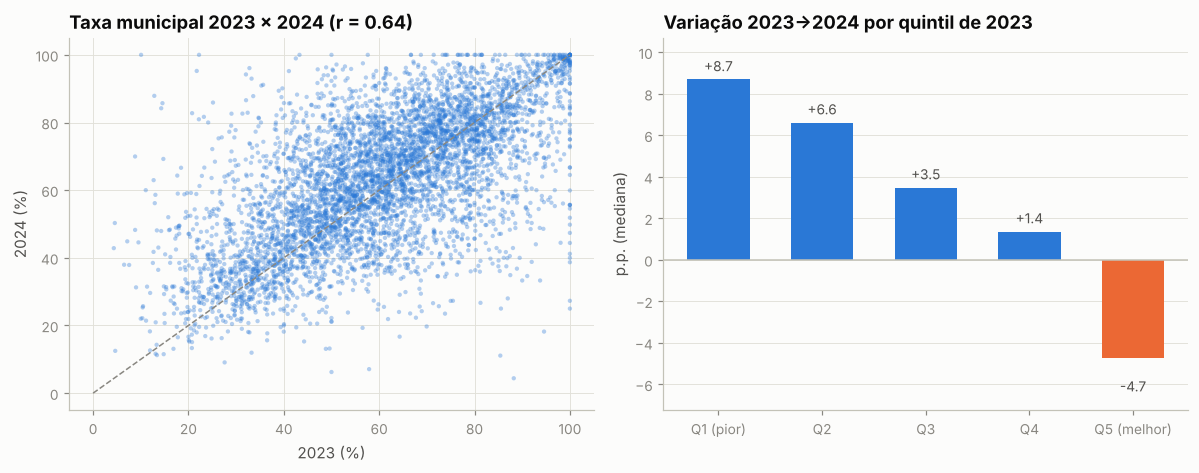

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
d = prof.dropna(subset=["taxa_2023", "taxa_2024"])
axes[0].scatter(d["taxa_2023"], d["taxa_2024"], s=8, alpha=0.35, color=vp.CAT[0], edgecolors="none")
axes[0].plot([0, 100], [0, 100], ls="--", color=vp.MUTED, lw=1)
r = d[["taxa_2023", "taxa_2024"]].corr().iloc[0, 1]
axes[0].set(title=f"Taxa municipal 2023 × 2024 (r = {r:.2f})", xlabel="2023 (%)", ylabel="2024 (%)")

d["faixa_2023"] = pd.qcut(d["taxa_2023"], 5, labels=["Q1 (pior)", "Q2", "Q3", "Q4", "Q5 (melhor)"])
g = d.groupby("faixa_2023", observed=True)["evolucao_23_24"].median()
axes[1].bar(g.index.astype(str), g.values, color=[vp.CAT[1] if v < 0 else vp.CAT[0] for v in g.values], width=0.6)
axes[1].axhline(0, color=vp.AXIS, lw=1)
axes[1].set_ylim(min(g.min() - 2.5, -1), g.max() + 2)
for i, v in enumerate(g.values):
    axes[1].text(i, v + (0.4 if v >= 0 else -1.6), f"{v:+.1f}", ha="center", color=vp.INK2, fontsize=9)
axes[1].set(title="Variação 2023→2024 por quintil de 2023", ylabel="p.p. (mediana)")
axes[1].grid(axis="x", visible=False)
fig.tight_layout(); vp.save(fig, "eda_persistencia"); plt.show()

**Leitura:** o resultado de 2023 explica boa parte de 2024 (r ≈ 0,6), mas há forte **regressão à média** — municípios
no pior quintil sobem e os do melhor quintil caem. Isso indica (i) ruído de medição em municípios pequenos e (ii) que o histórico
é um preditor útil, mas **não determinístico**.

## 6. Fatores associados à alfabetização do aluno (hipóteses)

(1852788, 29)


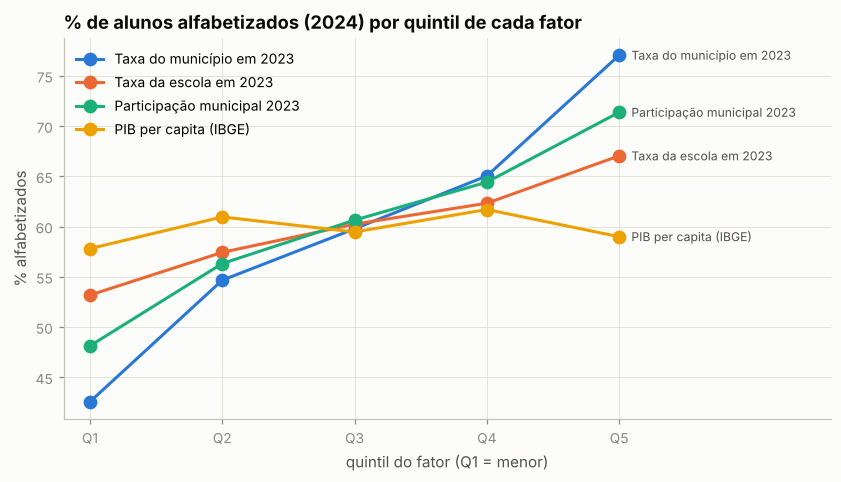

,Taxa do município em 2023,Taxa da escola em 2023,Participação municipal 2023,PIB per capita (IBGE)
Q1,42.60,53.20,48.10,57.80
Q2,54.70,57.40,56.30,61.00
Q3,59.80,60.20,60.60,59.50
Q4,65.00,62.30,64.40,61.70
Q5,77.00,67.00,71.40,59.00


In [10]:
base = pd.read_parquet(config.PROCESSED_DIR / "alunos_modelagem_2024.parquet") if (config.PROCESSED_DIR / "alunos_modelagem_2024.parquet").exists() else None
if base is None:
    from src.preprocessing.features import build_student_dataset
    base = build_student_dataset()
    base.to_parquet(config.PROCESSED_DIR / "alunos_modelagem_2024.parquet", index=False)
print(base.shape)

def taxa_por_quintil(col, rotulo):
    q = pd.qcut(base[col], 5, duplicates="drop")
    return base.groupby(q, observed=True)["alfabetizado"].mean().rename(rotulo).reset_index(drop=True)

hip = pd.concat([
    taxa_por_quintil("mun_taxa_rede_ant", "Taxa do município em 2023"),
    taxa_por_quintil("esc_pct_alf_ant", "Taxa da escola em 2023"),
    taxa_por_quintil("mun_participacao_ant", "Participação municipal 2023"),
    taxa_por_quintil("pib_per_capita_2010", "PIB per capita (IBGE)"),
], axis=1)
hip.index = ["Q1", "Q2", "Q3", "Q4", "Q5"]

fig, ax = plt.subplots(figsize=(9, 4.5))
for i, c in enumerate(hip.columns):
    ax.plot(hip.index, hip[c] * 100, marker="o", ms=8, color=vp.CAT[i], label=c)
    ax.annotate(c, (4, hip[c].iloc[-1] * 100), xytext=(8, 0), textcoords="offset points", va="center", fontsize=8, color=vp.INK2)
ax.set(title="% de alunos alfabetizados (2024) por quintil de cada fator", ylabel="% alfabetizados", xlabel="quintil do fator (Q1 = menor)")
ax.legend(loc="upper left"); ax.set_xlim(-0.2, 5.6)
vp.save(fig, "eda_hipoteses_quintis"); plt.show()
(hip * 100).round(1)

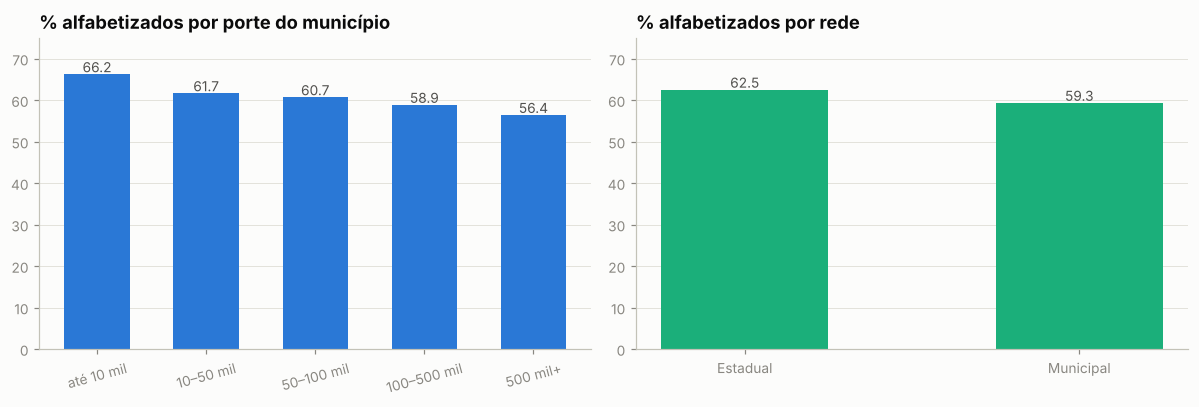

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ordem_porte = ["até 10 mil", "10–50 mil", "50–100 mil", "100–500 mil", "500 mil+"]
g = base.groupby("porte_municipio")["alfabetizado"].mean().reindex(ordem_porte) * 100
axes[0].bar(g.index, g.values, color=vp.CAT[0], width=0.6)
for i, v in enumerate(g.values): axes[0].text(i, v + 0.5, f"{v:.1f}", ha="center", fontsize=9, color=vp.INK2)
axes[0].set(title="% alfabetizados por porte do município", ylim=(0, 75)); axes[0].tick_params(axis="x", rotation=15)
axes[0].grid(axis="x", visible=False)
g = base.groupby("rede")["alfabetizado"].agg(["mean", "size"])
g = g[g["size"] > 1000]["mean"] * 100
axes[1].bar(g.index, g.values, color=vp.CAT[2], width=0.5)
for i, v in enumerate(g.values): axes[1].text(i, v + 0.5, f"{v:.1f}", ha="center", fontsize=9, color=vp.INK2)
axes[1].set(title="% alfabetizados por rede", ylim=(0, 75)); axes[1].grid(axis="x", visible=False)
fig.tight_layout(); vp.save(fig, "eda_porte_rede"); plt.show()

## 7. Correlações

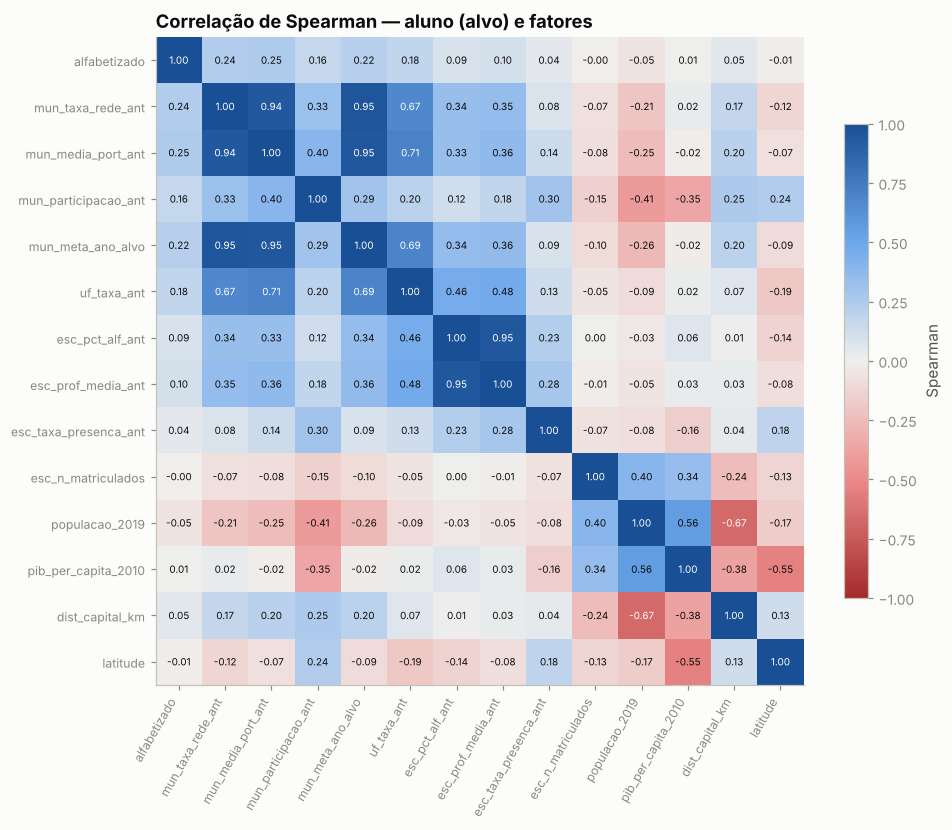

,spearman_com_alvo
mun_media_port_ant,0.25
mun_taxa_rede_ant,0.24
mun_meta_ano_alvo,0.22
uf_taxa_ant,0.18
mun_participacao_ant,0.16
esc_prof_media_ant,0.10
esc_pct_alf_ant,0.09
dist_capital_km,0.05
esc_taxa_presenca_ant,0.04
pib_per_capita_2010,0.01


In [12]:
cols = ["alfabetizado", "mun_taxa_rede_ant", "mun_media_port_ant", "mun_participacao_ant", "mun_meta_ano_alvo",
        "uf_taxa_ant", "esc_pct_alf_ant", "esc_prof_media_ant", "esc_taxa_presenca_ant", "esc_n_matriculados",
        "populacao_2019", "pib_per_capita_2010", "dist_capital_km", "latitude"]
amostra = base.sample(min(200_000, len(base)), random_state=config.RANDOM_STATE)
corr = amostra[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(corr, cmap=vp.DIV_CMAP.reversed(), vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right", fontsize=8); ax.set_yticks(range(len(cols)), cols, fontsize=8)
ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color=vp.INK if abs(corr.iloc[i, j]) < 0.6 else "white")
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman")
ax.set_title("Correlação de Spearman — aluno (alvo) e fatores")
vp.save(fig, "eda_correlacao"); plt.show()
corr["alfabetizado"].drop("alfabetizado").sort_values(ascending=False).to_frame("spearman_com_alvo")

## 8. Riscos de *data leakage* identificados na EDA

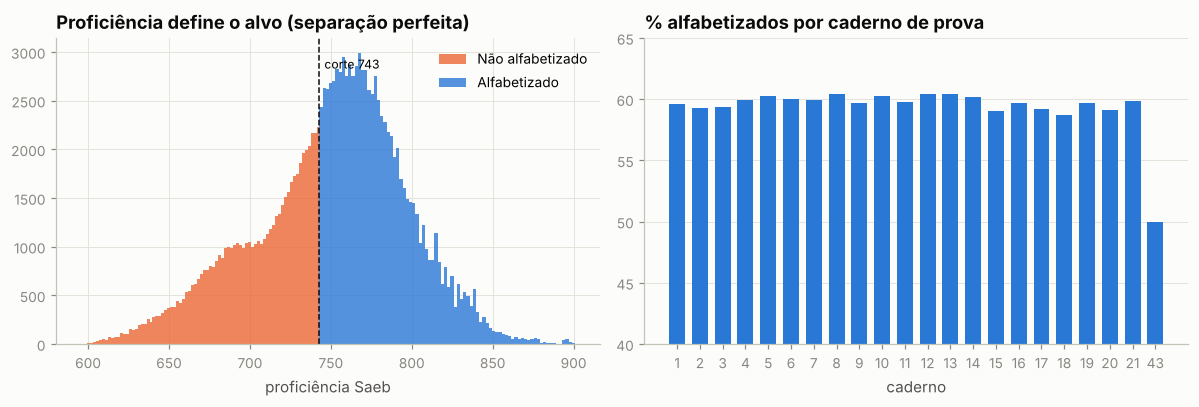

Concordância proficiência ≥ 743 ↔ alfabetizado: 100.0000%


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
p = presentes.sample(min(150_000, len(presentes)), random_state=1)
for v, c, lab in [(0, vp.CAT[1], "Não alfabetizado"), (1, vp.CAT[0], "Alfabetizado")]:
    axes[0].hist(p.loc[p.alfabetizado == v, "proficiencia"], bins=80, color=c, alpha=0.8, label=lab)
axes[0].axvline(config.PONTO_CORTE, color=vp.INK, ls="--", lw=1)
axes[0].text(config.PONTO_CORTE + 3, axes[0].get_ylim()[1] * 0.9, "corte 743", fontsize=8)
axes[0].set(title="Proficiência define o alvo (separação perfeita)", xlabel="proficiência Saeb"); axes[0].legend()

g = presentes.groupby("caderno")["alfabetizado"].mean() * 100
axes[1].bar(g.index.astype(str), g.values, color=vp.CAT[0], width=0.7)
axes[1].set(title="% alfabetizados por caderno de prova", xlabel="caderno", ylim=(40, 65)); axes[1].grid(axis="x", visible=False)
fig.tight_layout(); vp.save(fig, "eda_leakage"); plt.show()

print("Concordância proficiência ≥ 743 ↔ alfabetizado:", f"{((presentes.proficiencia >= 743).astype(int) == presentes.alfabetizado).mean():.4%}")

| Variável | Por que vaza | Decisão |
|---|---|---|
| `proficiencia` | O alvo é **definido** por proficiência ≥ 743 (concordância de 100%) | **removida** |
| `preenchimento_caderno`, `presenca` | Só existem após a prova; definem quem tem alvo observado | removidas (usadas apenas como filtro) |
| `peso_aluno` | Calculado pelo INEP após a aplicação (calibra participação) | removida |
| Taxa do município/escola **em 2024** | Contém o resultado do próprio aluno | substituída pela taxa de **2023** (T-1) |
| Alunos do mesmo município em treino e teste | Correlação intra-grupo infla a métrica | **split agrupado por município** |
| `caderno` | Atribuição aleatória — sem sinal (variação < 1 p.p., exceto caderno 1) | não usada |

## 9. Hipóteses e decisões de modelagem

**Hipóteses formuladas:**
1. **H1 — Histórico territorial:** municípios/escolas com melhores resultados em 2023 terão mais alunos alfabetizados em 2024. ✔ forte gradiente (≈ 43% → 77% entre quintis municipais).
2. **H2 — Desigualdade regional:** Norte e Nordeste concentram as menores taxas. ✔ confirmada — porém o Ceará é exceção positiva (>85%).
3. **H3 — Riqueza:** PIB per capita mais alto → mais alfabetização. ✘ relação fraca e não monotônica no nível do aluno: gestão educacional pesa mais que renda média.
4. **H4 — Porte:** municípios pequenos têm desempenho igual ou superior. ✔ municípios de até 10 mil habitantes lideram.
5. **H5 — Engajamento:** maior participação na avaliação associa-se a melhor desempenho. ✔ forte gradiente (≈ 48% → 71% entre quintis) — participação é um *proxy* de organização da rede.
6. **H6 — Choque regional 2024:** o Sul caiu de 2023 para 2024 (mediana negativa), concentrado no RS — compatível com as enchentes de maio/2024 que interromperam o ano letivo. Fator externo **não capturado** pelo histórico.

**Decisões para o notebook 02:**
* Unidade: **aluno presente** de 2024; alvo `alfabetizado`.
* Features: contexto de **2023** (escola, município, UF), metas 2024 (definidas a priori), território e socioeconomia (IBGE).
* Validação: treino/validação/teste **agrupados por município** + CV com `GroupKFold`.
* Métricas: ROC-AUC (ordenação de risco), acurácia balanceada, recall de "não alfabetizado", Brier (calibração).
* Expectativa realista: a alfabetização individual depende de fatores ausentes nas bases públicas (família, professor, frequência) — o
  modelo deve ser lido como **risco contextual**, cujo maior valor aparece quando agregado por escola/município.